# Exercise — Human Activity Recognition with deep neural networks

**Session 5 — Deep learning in practice (4/4)**

## The data

*Human Activity Recognition Using Smartphones* (UCI). Thirty volunteers each
performed six activities (WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS,
SITTING, STANDING, LAYING) with a smartphone on the waist. The embedded
accelerometer and gyroscope recorded 3-axial linear acceleration and 3-axial
angular velocity at 50 Hz; the signals were cut into 2.56 s sliding windows
and summarised into **561 time- and frequency-domain features** per window.

For each record the file contains:

* the 561-feature vector;
* the identifier of the **subject** who produced it;
* the **activity** label.

Source: <https://archive.ics.uci.edu/ml/datasets/human+activity+recognition+using+smartphones>

## What you have to do

1. Build a deep neural network for this 6-class problem.
2. Hold out a validation set and add early stopping.
3. Plot the learning curves and interpret them.
4. Repeat the experiment with a **subject-wise** split and explain the
   difference.
5. Produce a confusion matrix and say which activities get confused.
6. Compare with the SVM baseline provided at the end.

In [1]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Reproducibility: fix the seeds so that everybody in the room gets the same
# numbers. Without this, two students running the same code get different
# results -- which is fine in research, but confusing in a class.
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use the GPU if one is available. On a laptop this will normally be the CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: cpu


## 1. Loading the data

`HAR_clean.csv` is the pre-processed file built in the previous session: one
row per window, the 561 features first, then the subject identifier, then the
activity label.

In [2]:
import pandas as pd

folder = "/Users/filipa/desktop/notebooksAndData/data"   # o CSV tem 67 MB e fica fora do repositório

all_data = pd.read_csv(os.path.join(folder, "HAR_clean.csv"), index_col=0)
print("shape:", all_data.shape)
print("last three columns:", list(all_data.columns[-3:]))
all_data.iloc[:5, -4:]

shape: (10299, 563)
last three columns: ['angle(Z,gravityMean)', 'SubjectID', 'Activity']


,"angle(Y,gravityMean)","angle(Z,gravityMean)",SubjectID,Activity
0,0.179941,-0.058627,1,STANDING
1,0.180289,-0.054317,1,STANDING
2,0.180637,-0.049118,1,STANDING
3,0.181935,-0.047663,1,STANDING
4,0.185151,-0.043892,1,STANDING


Rather than relying on positional indexing (`iloc[:, :-2]`), let us name the
two non-feature columns explicitly — it makes the rest of the notebook much
easier to read, and it is the subject column that section 5 depends on.

In [3]:
subject_col = all_data.columns[-2]
activity_col = all_data.columns[-1]
feature_cols = all_data.columns[:-2]

X = all_data[feature_cols].values.astype(np.float32)
subjects = all_data[subject_col].values
y_raw = all_data[activity_col].values

print("X:", X.shape)
print("subjects:", len(np.unique(subjects)), "distinct")
print("\nexamples per activity:")
print(pd.Series(y_raw).value_counts())

X: (10299, 561)
subjects: 30 distinct

examples per activity:
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64


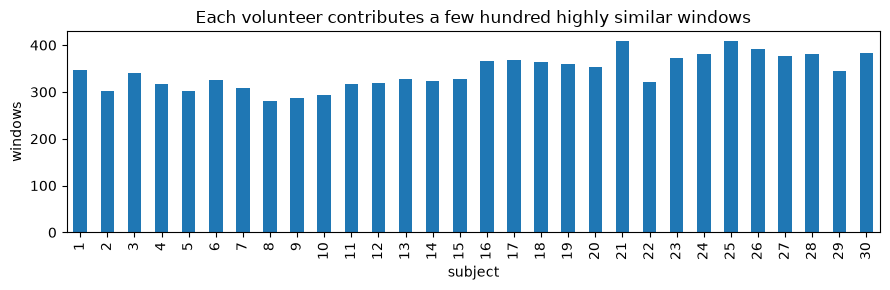

min     281.0
mean    343.3
max     409.0
Name: count, dtype: float64


In [4]:
# How many windows does each subject contribute?
per_subject = pd.Series(subjects).value_counts().sort_index()
plt.figure(figsize=(9, 3))
per_subject.plot(kind="bar")
plt.xlabel("subject"); plt.ylabel("windows")
plt.title("Each volunteer contributes a few hundred highly similar windows")
plt.tight_layout()
plt.show()
print(per_subject.describe()[["min", "mean", "max"]])

**Keep that plot in mind.** Each subject contributes several hundred windows,
and consecutive windows from the same person doing the same activity are
almost identical. We will come back to this in section 5.

## 2. Encoding the labels

`nn.CrossEntropyLoss` expects the targets as integer class indices
(0 … n_classes−1), not as one-hot vectors.

In [5]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(y_raw)
n_classes = len(le.classes_)

print("classes:", list(le.classes_))
print("encoded as:", list(range(n_classes)))

classes: ['LAYING', 'SITTING', 'STANDING', 'WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']
encoded as: [0, 1, 2, 3, 4, 5]


## 3. Splitting the data (random split, for now)

Train / validation / test, as usual. `stratify` keeps the class proportions
in each part, and `random_state` makes the split reproducible.

In [6]:
from sklearn.model_selection import train_test_split

def random_split(X, y, groups=None, seed=SEED):
    X_tmp, X_te, y_tmp, y_te = train_test_split(
        X, y, test_size=0.3, random_state=seed, stratify=y)
    X_tr, X_va, y_tr, y_va = train_test_split(
        X_tmp, y_tmp, test_size=0.2, random_state=seed, stratify=y_tmp)
    return X_tr, X_va, X_te, y_tr, y_va, y_te


X_tr, X_va, X_te, y_tr, y_va, y_te = random_split(X, y, subjects)
print("train", X_tr.shape, "| val", X_va.shape, "| test", X_te.shape)

train (5767, 561) | val (1442, 561) | test (3090, 561)


## 4. Scaling, tensors and loaders

The scaler is fitted on the training part only. Everything then goes into
`TensorDataset` / `DataLoader`.

In [7]:
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader


def prepare(X_tr, X_va, X_te, y_tr, y_va, y_te, batch_size=128):
    """Scale, convert to tensors and build the training DataLoader."""
    scaler = StandardScaler().fit(X_tr)
    to_t = lambda a: torch.from_numpy(scaler.transform(a).astype(np.float32))

    X_tr_t, X_va_t, X_te_t = to_t(X_tr), to_t(X_va).to(device), to_t(X_te).to(device)
    y_tr_t = torch.from_numpy(y_tr).long()
    y_va_t = torch.from_numpy(y_va).long().to(device)
    y_te_t = torch.from_numpy(y_te).long().to(device)

    loader = DataLoader(TensorDataset(X_tr_t, y_tr_t),
                        batch_size=batch_size, shuffle=True)
    return loader, (X_va_t, y_va_t), (X_te_t, y_te_t)


train_loader, (X_va_t, y_va_t), (X_te_t, y_te_t) = prepare(
    X_tr, X_va, X_te, y_tr, y_va, y_te)
print(len(train_loader), "training batches")

46 training batches


## 5. Task 1 — define the network

Build a feedforward network for 561 inputs and `n_classes` outputs.

Suggestions:

* 2 or 3 hidden layers (e.g. 256 → 128 → 64) with `nn.ReLU()`;
* the output layer has `n_classes` neurons and **no activation** — remember
  that `nn.CrossEntropyLoss` wants logits;
* optionally `nn.BatchNorm1d` and/or `nn.Dropout`. The conventional order is
  `Linear → BatchNorm1d → ReLU → Dropout`.

> Both `BatchNorm` and `Dropout` behave **differently in training and in
> evaluation**. That is what `model.train()` and `model.eval()` are for, and
> why the loop below is careful about them.

In [8]:
class HARNet(nn.Module):
    def __init__(self, in_features, n_classes, p_drop=0.3):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(in_features, 256),
            nn.ReLU(),
            nn.Dropout(p_drop),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(p_drop),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, n_classes),     # logits: a CrossEntropyLoss aplica o softmax
        )

    def forward(self, x):
        return self.net(x)

## 6. Task 2 — loss and optimiser

Which loss function fits a 6-class problem whose network returns logits?

In [9]:
def make_model(seed=SEED, lr=1e-3):
    torch.manual_seed(seed)
    model = HARNet(X.shape[1], n_classes).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    return model, criterion, optimizer


model, criterion, optimizer = make_model()
print(model)

HARNet(
  (net): Sequential(
    (0): Linear(in_features=561, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=128, out_features=64, bias=True)
    (7): ReLU()
    (8): Linear(in_features=64, out_features=6, bias=True)
  )
)


## 7. The training loop (provided)

Read it carefully — it is the loop from the regression notebook, with
accuracy added. Three details matter:

* `model.train()` at the start of each epoch and `model.eval()` before
  evaluating. **With `BatchNorm` in the model this is not cosmetic**: in
  training mode the layer normalises each batch by its own statistics *and
  updates its running averages*. Evaluating the test set in training mode
  therefore both gives the wrong answer and lets test data leak into the
  model. `torch.no_grad()` does **not** prevent this — only `eval()` does.
* the running loss is weighted by the batch size and divided by the number of
  examples, so that it is a true mean;
* we keep the best weights and restore them at the end (early stopping).

In [10]:
import copy


def evaluate(model, criterion, X_t, y_t):
    model.eval()
    with torch.no_grad():
        logits = model(X_t)
        loss = criterion(logits, y_t).item()
        acc = (logits.argmax(dim=1) == y_t).float().mean().item()
    return loss, acc


def train(model, criterion, optimizer, train_loader, val_data,
          epochs=60, patience=10, verbose=True):
    X_va_t, y_va_t = val_data
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_val, best_state, waited = float("inf"), None, 0

    for epoch in range(1, epochs + 1):
        model.train()
        running, n = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            loss = criterion(model(xb), yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running += loss.item() * xb.size(0)
            n += xb.size(0)
        train_loss = running / n

        val_loss, val_acc = evaluate(model, criterion, X_va_t, y_va_t)
        hist["train_loss"].append(train_loss)
        hist["val_loss"].append(val_loss)
        hist["val_acc"].append(val_acc)

        if val_loss < best_val - 1e-5:
            best_val, waited = val_loss, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            waited += 1

        if verbose and (epoch % 5 == 0 or epoch == 1):
            print(f"Epoch {epoch:3d} | train {train_loss:.4f} "
                  f"| val {val_loss:.4f} | val acc {val_acc:.4f}")

        if waited >= patience:
            if verbose:
                print(f"Early stopping at epoch {epoch}")
            break

    model.load_state_dict(best_state)
    return hist

In [11]:
hist = train(model, criterion, optimizer, train_loader, (X_va_t, y_va_t))

Epoch   1 | train 0.8171 | val 0.3050 | val acc 0.8564


Epoch   5 | train 0.1286 | val 0.0768 | val acc 0.9688


Epoch  10 | train 0.0594 | val 0.0636 | val acc 0.9743


Epoch  15 | train 0.0460 | val 0.0496 | val acc 0.9813


Epoch  20 | train 0.0305 | val 0.0329 | val acc 0.9868


Epoch  25 | train 0.0359 | val 0.0530 | val acc 0.9799


Epoch  30 | train 0.0294 | val 0.0591 | val acc 0.9799
Early stopping at epoch 30


## 8. Task 3 — learning curves

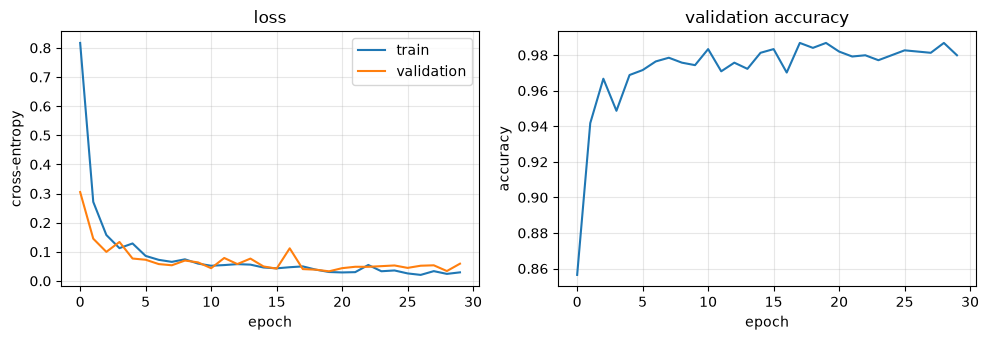

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(hist["train_loss"], label="train")
ax1.plot(hist["val_loss"], label="validation")
ax1.set_xlabel("epoch"); ax1.set_ylabel("cross-entropy")
ax1.legend(); ax1.grid(alpha=.3); ax1.set_title("loss")

ax2.plot(hist["val_acc"])
ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy")
ax2.grid(alpha=.3); ax2.set_title("validation accuracy")
plt.tight_layout()
plt.show()

In [13]:
test_loss, test_acc = evaluate(model, criterion, X_te_t, y_te_t)
print(f"Test accuracy (random split): {test_acc:.4f}")

Test accuracy (random split): 0.9832


> You may notice that the training loss is *higher* than the validation loss
> in the first epochs. That is not a bug: dropout is active during training
> and switched off at evaluation, so the model is literally handicapped while
> the training loss is being measured.

## 9. Task 4 — a subject-wise split

The accuracy above is suspiciously high. Here is why.

The 10 299 windows come from only 30 people. Consecutive windows of the same
person walking are nearly identical, so a random split puts almost-copies of
the same recording on both sides of the train/test line. The model can
succeed by recognising **the person**, not the activity — and it is never
asked to generalise to anyone new.

That is not how the model would be used. A real activity recogniser has to
work on a phone belonging to someone who was never in the training data.
The original UCI benchmark therefore splits **by subject**: 21 volunteers for
training, 9 for test.

Implement that split with `GroupShuffleSplit` (or by selecting subject ids by
hand), re-train the same network, and compare.

In [14]:
from sklearn.model_selection import GroupShuffleSplit


def subject_split(X, y, groups, seed=SEED):
    """Split so that no subject appears in more than one of the three sets."""
    outer = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=seed)
    tmp_idx, te_idx = next(outer.split(X, y, groups))

    inner = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
    tr_rel, va_rel = next(inner.split(X[tmp_idx], y[tmp_idx], groups[tmp_idx]))
    tr_idx, va_idx = tmp_idx[tr_rel], tmp_idx[va_rel]

    return (X[tr_idx], X[va_idx], X[te_idx], y[tr_idx], y[va_idx], y[te_idx],
            groups[tr_idx], groups[va_idx], groups[te_idx])


(Xg_tr, Xg_va, Xg_te, yg_tr, yg_va, yg_te,
 g_tr, g_va, g_te) = subject_split(X, y, subjects)

print("subjects in train:", sorted(np.unique(g_tr)))
print("subjects in val  :", sorted(np.unique(g_va)))
print("subjects in test :", sorted(np.unique(g_te)))
assert not (set(g_tr) | set(g_va)) & set(g_te), "a subject leaked into the test set!"

subjects in train: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(12), np.int64(14), np.int64(15), np.int64(17), np.int64(19), np.int64(20), np.int64(22), np.int64(26), np.int64(27), np.int64(30)]
subjects in val  : [np.int64(1), np.int64(2), np.int64(11), np.int64(21), np.int64(23)]
subjects in test : [np.int64(9), np.int64(10), np.int64(13), np.int64(16), np.int64(18), np.int64(24), np.int64(25), np.int64(28), np.int64(29)]


In [15]:
g_loader, g_val, g_test = prepare(Xg_tr, Xg_va, Xg_te, yg_tr, yg_va, yg_te)

model_g, criterion_g, optimizer_g = make_model()
hist_g = train(model_g, criterion_g, optimizer_g, g_loader, g_val, verbose=False)

g_loss, g_acc = evaluate(model_g, criterion_g, *g_test)

print(f"random split  -> test accuracy {test_acc:.4f}")
print(f"subject split -> test accuracy {g_acc:.4f}")
print(f"difference    -> {100 * (test_acc - g_acc):.1f} percentage points")

random split  -> test accuracy 0.9832
subject split -> test accuracy 0.8767
difference    -> 10.6 percentage points


**Expect a drop of a few percentage points.** The second number is the honest
one: it answers the question "how well will this work on a new user?", while
the first answers "how well does this work on more data from the same 30
people?".

The lesson generalises well beyond this dataset. Whenever your examples come
in natural groups — patients, subjects, images from the same specimen,
sequences from the same organism, measurements from the same batch — the
split has to respect those groups, or the reported performance is fiction.
This is one of the most common methodological errors in applied machine
learning papers.

## 10. Task 5 — confusion matrix

Which activities does the model confuse? Produce the confusion matrix for the
**subject-wise** model.

[[486 103  10   0   0   0]
 [  0 502  41   0   0   1]
 [  0 135 449   0   0   0]
 [  0   0   0 505   2   1]
 [  0   0   0  12 377  47]
 [  0   0   0  30   7 447]]


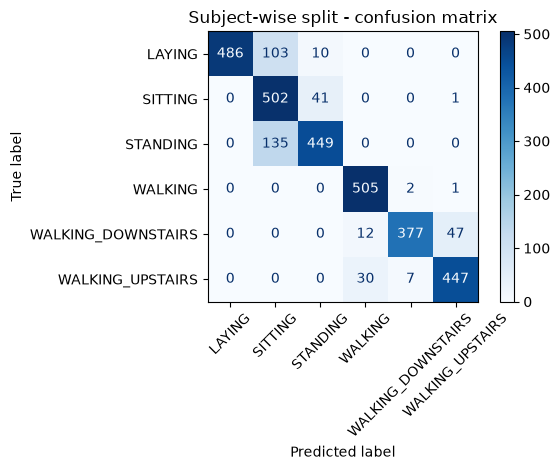

                    precision    recall  f1-score   support

            LAYING      1.000     0.811     0.896       599
           SITTING      0.678     0.923     0.782       544
          STANDING      0.898     0.769     0.828       584
           WALKING      0.923     0.994     0.957       508
WALKING_DOWNSTAIRS      0.977     0.865     0.917       436
  WALKING_UPSTAIRS      0.901     0.924     0.912       484

          accuracy                          0.877      3155
         macro avg      0.896     0.881     0.882      3155
      weighted avg      0.895     0.877     0.879      3155



In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

X_te_g, y_te_g = g_test
model_g.eval()
with torch.no_grad():
    pred_g = model_g(X_te_g).argmax(dim=1).cpu().numpy()
true_g = y_te_g.cpu().numpy()

cm = confusion_matrix(true_g, pred_g)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(cmap="Blues", xticks_rotation=45)
plt.title("Subject-wise split - confusion matrix")
plt.tight_layout()
plt.show()

print(classification_report(true_g, pred_g, target_names=le.classes_, digits=3))

**What to look for.** The three walking activities are usually well
separated — they produce very different acceleration patterns. The errors
concentrate on SITTING vs STANDING, which is unsurprising: in both the phone
is nearly motionless and the only signal is the orientation of the gravity
vector, which depends on how the person is sitting and on where exactly the
phone sits on the waist. That failure mode is a property of the sensors, not
of the network — no amount of extra layers will fix it.

## 11. Task 6 — compare with a shallow model

An SVM with an RBF kernel is a strong baseline on this dataset. Run it on the
**same** subject-wise split so that the comparison is fair.

> The full grid (`C` × `gamma` × kernels, with 5-fold cross-validation on
> 561 features) takes several minutes. The grid below is reduced on purpose;
> widen it at home if you want.

In [17]:
import time
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler

scaler_g = StandardScaler().fit(Xg_tr)
Xg_tr_s, Xg_te_s = scaler_g.transform(Xg_tr), scaler_g.transform(Xg_te)

t0 = time.time()
grid = GridSearchCV(SVC(kernel="rbf"),
                    {"C": [1, 100], "gamma": [0.001, 0.01]},
                    cv=3, n_jobs=-1)
grid.fit(Xg_tr_s, yg_tr)
print(f"best: {grid.best_estimator_}  ({time.time() - t0:.0f} s)")

svm_acc = grid.score(Xg_te_s, yg_te)
print(f"\nSVM            -> test accuracy {svm_acc:.4f}")
print(f"neural network -> test accuracy {g_acc:.4f}")

best: SVC(C=100, gamma=0.001)  (8 s)



SVM            -> test accuracy 0.8948
neural network -> test accuracy 0.8767


## 12. Questions to discuss

1. The two models end up within a couple of points of each other. On a
   tabular dataset of 10 000 examples and 561 **hand-engineered** features,
   is that surprising? What would have to change for deep learning to show a
   clear advantage here?
2. The 561 features were built by signal-processing experts (means, standard
   deviations, FFT coefficients, correlations…). A 1-D convolutional network
   could learn from the **raw** 50 Hz signals instead. What would it gain,
   and what would it cost?
3. Your learning curves: did early stopping trigger? At which epoch? What
   happens if you remove dropout?
4. Suppose you report the random-split accuracy in a paper and a reviewer
   asks whether the model works on new users. What do you answer?

## Optional extensions

* Leave-one-subject-out cross-validation (30 folds) to get a confidence
  interval instead of a single number.
* Merge SITTING and STANDING into one class and see how much of the remaining
  error disappears.
* Train on the raw inertial signals with `nn.Conv1d` instead of the 561
  features.

In [18]:
# Pergunta 3: épocas treinadas e efeito de retirar o dropout (mesmo split por sujeito)
torch.manual_seed(SEED)
model_nd = HARNet(X.shape[1], n_classes, p_drop=0.0).to(device)
criterion_nd = nn.CrossEntropyLoss()
optimizer_nd = optim.Adam(model_nd.parameters(), lr=1e-3)
hist_nd = train(model_nd, criterion_nd, optimizer_nd, g_loader, g_val, verbose=False)
_, nd_acc = evaluate(model_nd, criterion_nd, *g_test)

print(f"random split:  {len(hist['val_loss'])} épocas")
print(f"subject split: {len(hist_g['val_loss'])} épocas | test acc {g_acc:.4f}")
print(f"sem dropout:   {len(hist_nd['val_loss'])} épocas | test acc {nd_acc:.4f}")

random split:  30 épocas
subject split: 14 épocas | test acc 0.8767
sem dropout:   23 épocas | test acc 0.8777


## Respostas

**Split aleatório vs por sujeito.** A accuracy desce de 0.983 para 0.877 (10.6 pontos). No split aleatório há janelas quase iguais da mesma pessoa no treino e no teste; o valor honesto para um utilizador novo é o do split por sujeito.

**Matriz de confusão.** A maior confusão é STANDING → SITTING (135) e SITTING → STANDING (41): nas duas o telemóvel está quase parado. Há ainda 103 janelas de LAYING classificadas como SITTING, o que baixa o recall de LAYING para 0.811. Nas atividades a andar, a maior confusão é WALKING_DOWNSTAIRS → WALKING_UPSTAIRS (47).

**1. É surpreendente que os dois modelos fiquem próximos?** Não: SVM 0.895, rede 0.877. As 561 features já foram construídas por especialistas e há só cerca de 10 000 exemplos, o que favorece modelos clássicos. O deep learning ganharia vantagem com muito mais dados e com dados em bruto, onde pode aprender a representação.

**2. CNN 1-D sobre os sinais em bruto.** Ganharia a capacidade de aprender padrões temporais sem engenharia manual de features. Custaria mais dados, mais tempo de treino, mais hiperparâmetros e menos interpretabilidade.

**3. Early stopping e dropout.** O early stopping atuou nos dois casos: 30 épocas no split aleatório e 14 no split por sujeito. Sem dropout, parou às 23 épocas com accuracy 0.878, praticamente igual a 0.877 com dropout; aqui o dropout não mudou o resultado.

**4. Resposta ao revisor.** Que a accuracy do split aleatório não mede o desempenho em utilizadores novos, porque há amostras muito parecidas da mesma pessoa em treino e teste. O número a reportar é o do split por sujeito (0.877), de preferência com validação cruzada por sujeito para ter um intervalo de confiança.